In [31]:
import numpy as np
np.long = np.int_
np.ulong = np.uint

if not hasattr(np, "bool"):
    np.bool = bool
    
import mxnet as mx   
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import pickle
from collections import Counter
from torch.utils.data import Dataset
from pathlib import Path
from PIL import Image
from io import BytesIO
import pandas as pd
import math

In [4]:
# !pip install "numpy<2.0"

In [6]:
ROOT_PATH = "data/faces_webface_112x112"

In [20]:
!ls data/faces_webface_112x112

agedb_30.bin  cfp_ff.bin  cplfw.bin  property  train.csv  train.lst
calfw.bin     cfp_fp.bin  lfw.bin    train     train.idx  train.rec


### lst

In [8]:
data_dir = Path(ROOT_PATH)

train_lst_path = data_dir / "train.lst"

with open(train_lst_path, "r") as f:
    train_lst = f.readlines()

In [9]:
len(train_lst)

494149

In [10]:
print(train_lst[0])

0	/raid5data/dplearn/CASIA-WebFace/0000045/001.jpg	0	57	59	187	212	93.3661	151.566	127.419	107.732	158.046	115.133	105.133	139.307	179.872	170.261



### idx & rec

In [11]:
record = mx.recordio.MXIndexedRecordIO(
    f"{ROOT_PATH}/train.idx",
    f"{ROOT_PATH}/train.rec",
    "r",
)

In [12]:
len(train_lst), len(record.keys)

(494149, 501196)

### save images

In [13]:
def convert_recordio_to_dataframe(root_path):
    train_dir = Path(root_path) / "train"
    train_dir.mkdir(parents=True, exist_ok=True)

    data = []

    for idx, key in enumerate(record.keys):
        packed = record.read_idx(key)
        header, image_bytes = mx.recordio.unpack(packed)

        if header.flag != 0:
            continue

        image = Image.open(BytesIO(image_bytes)).convert("RGB")

        image_name = f"img_{idx}.jpg"
        image.save(train_dir / image_name, format="JPEG")

        data.append({
            "path": f"/train/{image_name}",
            "label": int(header.label),
        })

    record.close()

    return pd.DataFrame(data, columns=["path", "label"])

In [14]:
df = convert_recordio_to_dataframe(ROOT_PATH)

In [15]:
len(df)

490623

In [18]:
len(df['label'].unique())

10572

In [19]:
df.to_csv(ROOT_PATH + "/" + "train.csv", index=False)

In [21]:
df['label'].dtype

dtype('int64')

### dataset

In [23]:
class LabeledFaceDataset(Dataset):
    def __init__(self, csv_path):
        self.df = pd.read_csv(csv_path)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        root_path = Path(ROOT_PATH)
        
        image_path = root_path / row["path"].lstrip("/")
        image = Image.open(image_path).convert("RGB")
        label = int(row["label"])
        return image, label

In [24]:
dataset = LabeledFaceDataset(csv_path=f"{ROOT_PATH}/train.csv",)

In [25]:
len(dataset)

490623

In [27]:
len(dataset.df['label'].unique())

10572

In [28]:
image, label = dataset[0]

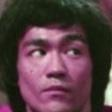

In [29]:
image

In [30]:
label

0

### show image and labels

In [32]:
def get_top_labels(dataset, top_n=10):
    return dataset.df["label"].value_counts().head(top_n)

In [38]:
def show_label_images(dataset, label, max_images=20):
    df_label = dataset.df[dataset.df["label"] == label].head(max_images)

    if df_label.empty:
        print(f"No images found for label {label}")
        return

    n_images = len(df_label)
    n_cols = min(5, n_images)
    n_rows = math.ceil(n_images / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3 * n_rows))
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]
    root_path = Path(ROOT_PATH)
    
    for ax, (_, row) in zip(axes, df_label.iterrows()):
        image_path = root_path / row["path"].lstrip("/")
        image = Image.open(image_path).convert("RGB")

        ax.imshow(image)
        ax.set_title(f"Label: {label}")
        ax.axis("off")

    for ax in axes[n_images:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [34]:
top_labels = get_top_labels(dataset, top_n=10)
top_labels

label
819     802
3410    744
138     710
1321    651
3384    648
2188    631
3024    628
872     621
2749    615
4111    609
Name: count, dtype: int64

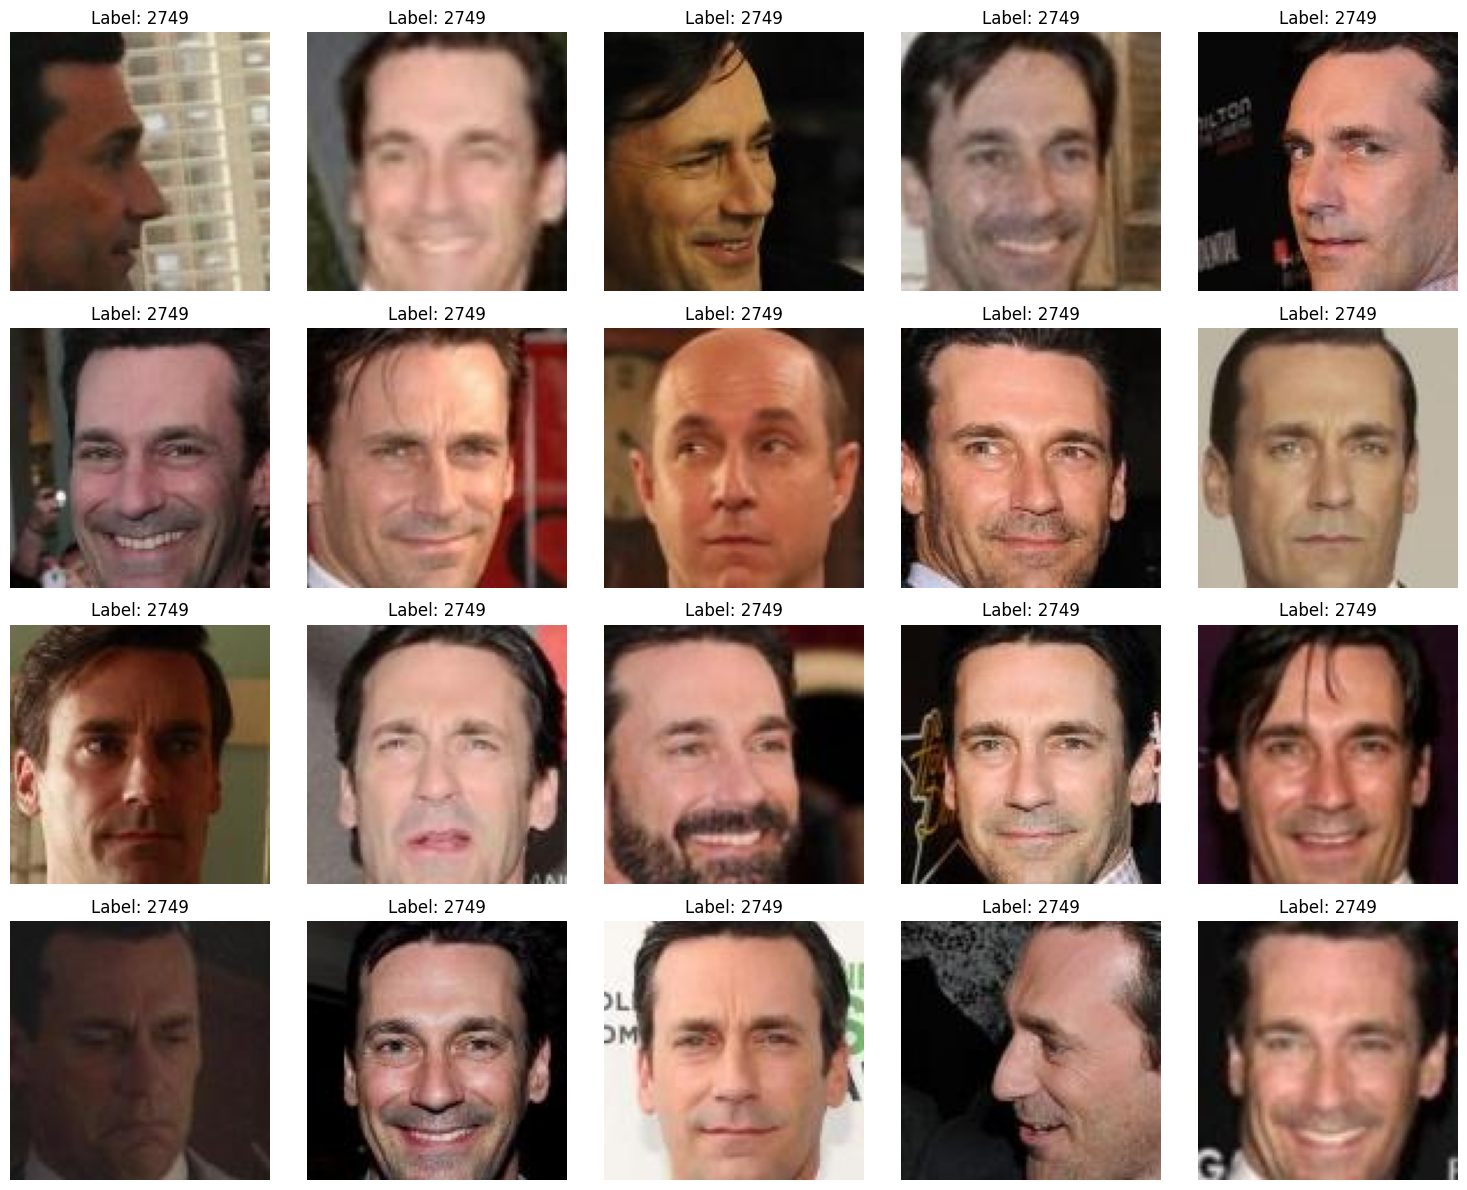

In [46]:
show_label_images(dataset, label=2749, max_images=20)

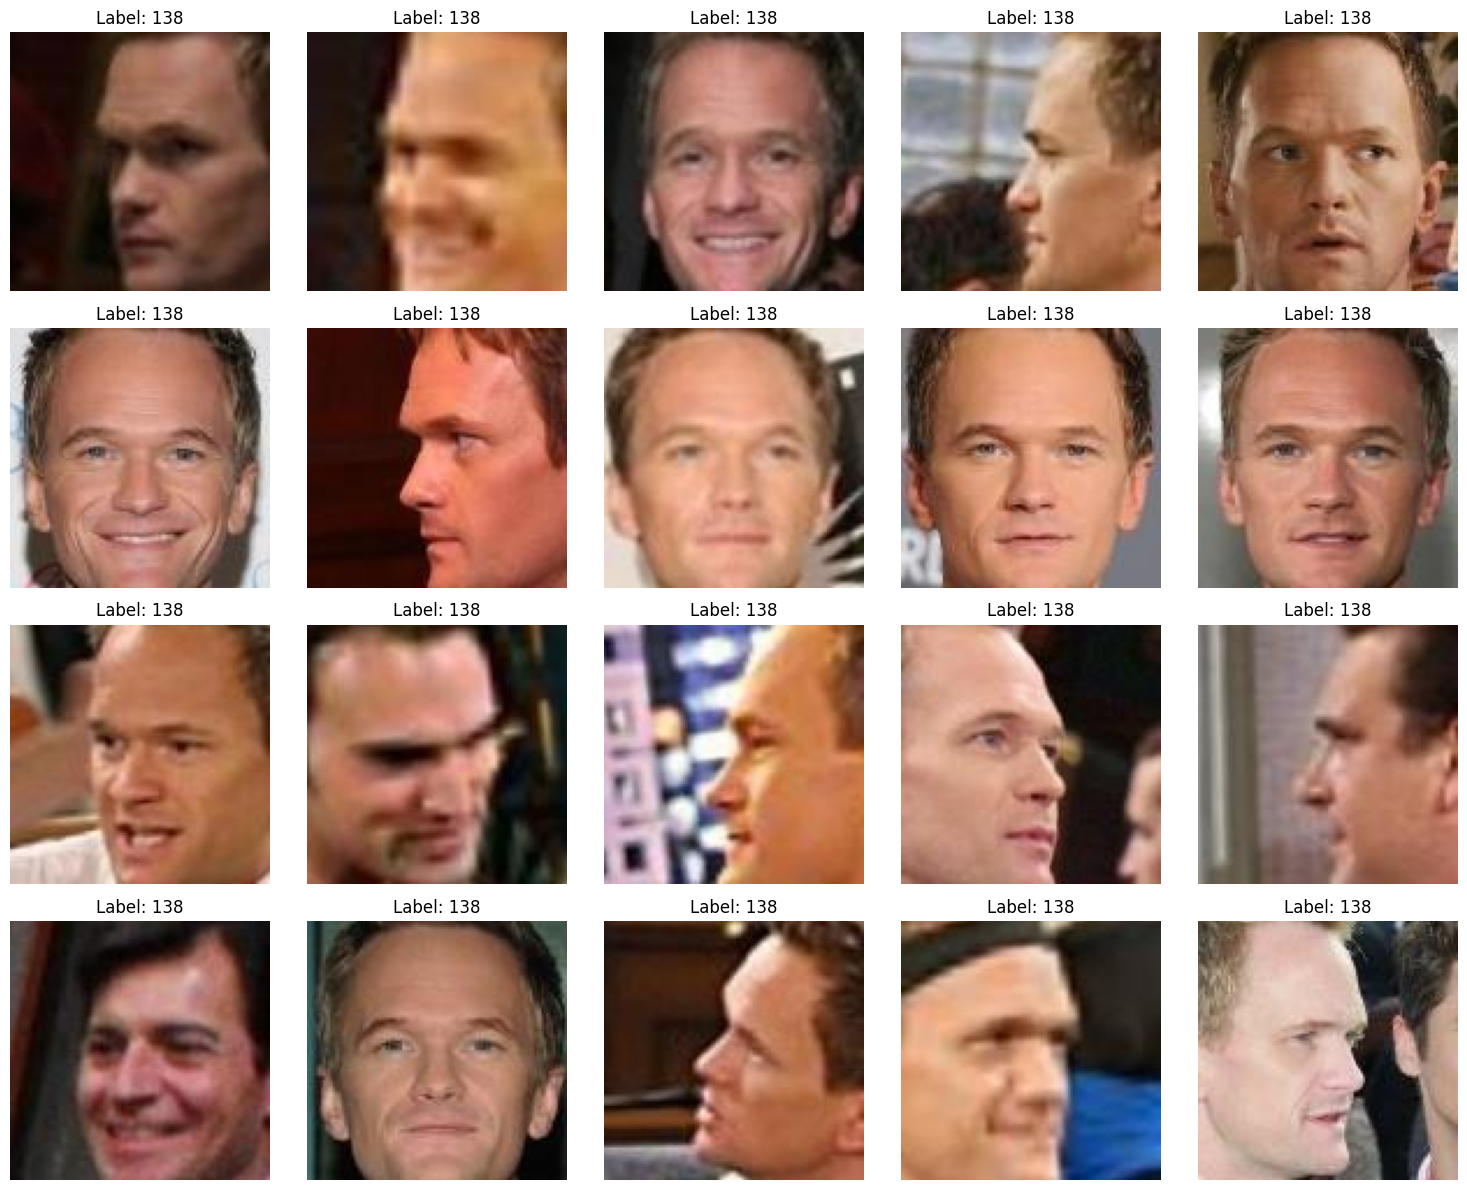

In [41]:
show_label_images(dataset, label=138, max_images=20)